# op

          Day  Cushing OK WTI Spot Price FOB $/bbl
0  01/21/2025                                76.79
1  01/17/2025                                78.56
2  01/16/2025                                79.35
3  01/15/2025                                80.73
4  01/14/2025                                78.20


(np.float64(0.9698968204699894), np.float64(0.028146146972452817))

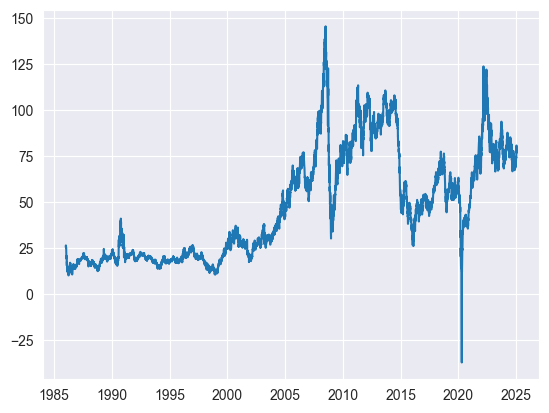

In [2]:
import numpy as np
import pandas as pd
import ordpy as op
import matplotlib.pyplot as plt
from datetime import datetime

wti = pd.read_csv("data/Spot_Prices_WTI.csv", header=6)
print(wti.head())


wti_datetime_values = [datetime.strptime(date, '%m/%d/%Y').date() for date in wti["Day"]]
wti_values = wti["Cushing OK WTI Spot Price FOB $/bbl"]
plt.plot(wti_datetime_values, wti_values)
op.complexity_entropy(wti_values)

In [3]:
complexities = []
entropies = []

for alpha in np.linspace(0, 1, 10):
    complexity, entropy = op.renyi_complexity_entropy(data=wti_values, alpha=alpha)
    complexities.append(complexity)
    entropies.append(entropy)

print(complexities)

[np.float64(1.0), np.float64(0.9967567043278254), np.float64(0.9934791627589463), np.float64(0.9901709115482478), np.float64(0.9868356857986821), np.float64(0.9834773992392518), np.float64(0.9801001212729236), np.float64(0.9767080515784822), np.float64(0.9733054926189785), np.float64(0.9698968204699895)]


In [4]:
# # V1
# # def plot_complexity_entropy(
#     data,
#     d_range=[3, 4, 5],
#     title="Complexity–Entropy Curves for Different Embedding Dimensions",
#     df_name="",
#     color="blue"
#     ):
#     for d in d_range:
#         entropies, complexities = zip(*op.renyi_complexity_entropy(
#             data=data,
#             alpha=np.linspace(0, 1, 10),
#             dx=d,
#         ))

#         plt.plot(
#             entropies,
#             complexities,
#             label="{}, d={}".format(
#                 df_name,
#                 d,
#             ),
#             color=color,
#         )
#         plt.plot(entropies[0], complexities[0], "*", color=color)
#         plt.xlabel("Entropy")
#         plt.ylabel("Complexity")
#         plt.title(title)
#         plt.legend()


#     # plt.show()

# # V2
# import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors
# import numpy as np

# def plot_complexity_entropy(
#     data,
#     d_range=[3, 4, 5],
#     title="Complexity–Entropy Curves for Different Embedding Dimensions",
#     df_name="",
#     color="blue"
# ):
#     n = len(d_range)
#     base_color = mcolors.to_rgb(color)
#     cmap = mcolors.LinearSegmentedColormap.from_list('gradient', [(0.7, 0.7, 0.7), base_color])
#     colors = [cmap(i / (n - 1)) for i in range(n)]
    
#     for idx, d in enumerate(d_range):
#         entropies, complexities = zip(*op.renyi_complexity_entropy(
#             data=data,
#             alpha=np.linspace(0, 1, 10),
#             dx=d,
#         ))

#         plt.plot(
#             entropies,
#             complexities,
#             label="{}, d={}".format(df_name, d),
#             color=colors[idx],
#         )
#         plt.plot(entropies[0], complexities[0], "*", color=colors[idx])
    
#     plt.xlabel("Entropy")
#     plt.ylabel("Complexity")
#     plt.title(title)
#     plt.legend()
#     # plt.show()  # Uncomment to display the plot

# # Example usage:
# # plot_complexity_entropy(data=my_data, color='blue')

# # V3
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

def lighten_color(color, amount=0.5):
    """Lighten the given color by a given amount (0 to 1)."""
    c = np.array(mcolors.to_rgb(color))
    # Increase brightness without reaching white
    return tuple(np.clip(c + (1 - c) * amount, 0, 1))

def darken_color(color, amount=0.5):
    """Darken the given color by a given amount (0 to 1)."""
    c = np.array(mcolors.to_rgb(color))
    return tuple(np.clip(c * (1 - amount), 0, 1))

def plot_complexity_entropy(
    data,
    d_range=[3, 4, 5],
    title="Complexity–Entropy Curves for Different Embedding Dimensions",
    df_name="",
    color="blue"
):
    n = len(d_range)
    dark_color = darken_color(color, 0.7)
    light_color = lighten_color(color, 0.7)
    
    # Create a colormap that interpolates between the dark and light variants.
    cmap = mcolors.LinearSegmentedColormap.from_list('gradient', [dark_color, light_color])
    colors = [cmap(i / (n - 1)) for i in range(n)]
    
    for idx, d in enumerate(d_range):
        entropies, complexities = zip(*op.renyi_complexity_entropy(
            data=data,
            alpha=np.linspace(0, 1, 10),
            dx=d,
        ))
        plt.plot(
            entropies,
            complexities,
            label="{}, d={}".format(df_name, d),
            color=colors[idx],
        )
        plt.plot(entropies[0], complexities[0], "*", color=colors[idx])
    
    plt.xlabel("Entropy")
    plt.ylabel("Complexity")
    plt.title(title)
    plt.legend()
    # plt.show()  # Uncomment to display the plot

# Example usage:
# plot_complexity_entropy(data=my_data, color='blue')




# Add Complexity Entropy Causality Plane

In [48]:
import ordpy as op
import seaborn as sns

def plot_envelope():
    min_ce = op.minimum_complexity_entropy()
    max_ce = op.maximum_complexity_entropy(dx=5, dy=1)

    plt.plot(
        min_ce[:, 0],
        min_ce[:, 1],
        color="black",
        linewidth=0.8,
    )
    plt.plot(
        max_ce[:, 0],
        max_ce[:, 1],
        color="black",
        linewidth=0.8,
    )

    plt.xlabel("Entropy")
    plt.ylabel("Complexity")

Text(0.5, 1.0, 'Envelope')

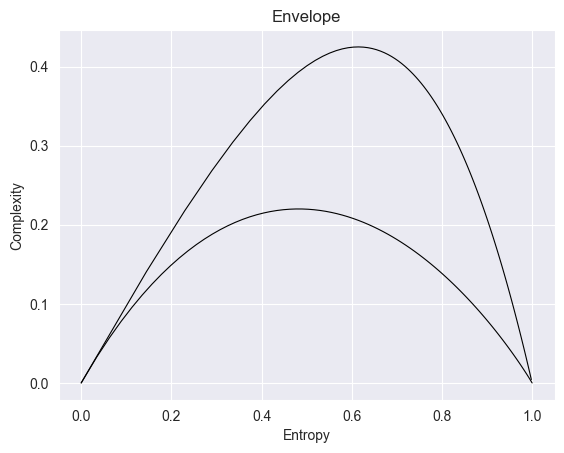

In [49]:
plot_envelope()
plt.title("Envelope")

# Nice Plots

## WTI Crude Oil

          Day  Cushing OK WTI Spot Price FOB $/bbl
0  01/21/2025                                76.79
1  01/17/2025                                78.56
2  01/16/2025                                79.35
3  01/15/2025                                80.73
4  01/14/2025                                78.20


Text(0.5, 1.0, 'WTI Crude Oil')

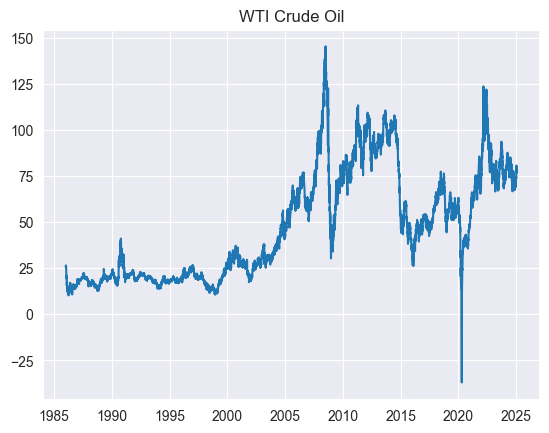

In [7]:
from datetime import datetime
wti = pd.read_csv("data/Spot_Prices_WTI.csv", header=6)
print(wti.head())


wti_datetime_values = [datetime.strptime(date, '%m/%d/%Y').date() for date in wti["Day"]]
wti_values = wti["Cushing OK WTI Spot Price FOB $/bbl"]
plt.plot(wti_datetime_values, wti_values)
plt.title("WTI Crude Oil")

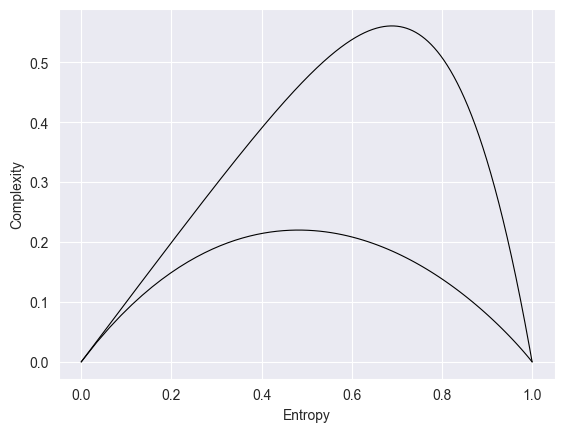

In [47]:
plot_envelope()

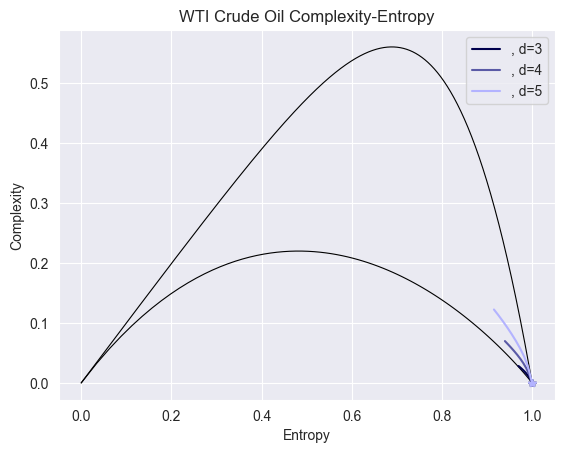

In [8]:
plot_envelope()
plot_complexity_entropy(wti_values, title="WTI Crude Oil Complexity-Entropy")

## SantaFe (Big)

Text(0.5, 1.0, 'SantaFe')

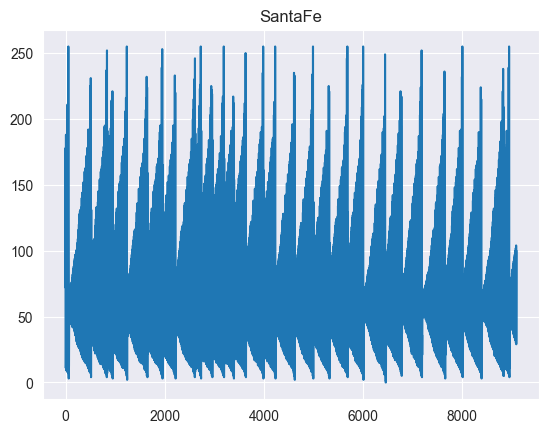

In [9]:
santafe = pd.read_csv("data/SantaFeA2.csv", header=None)

plt.plot(santafe)
plt.title("SantaFe")

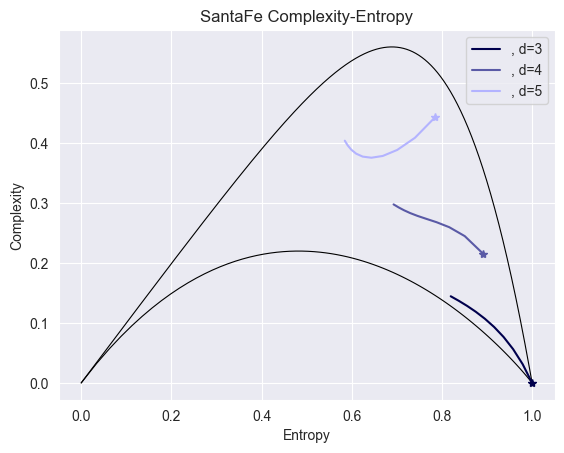

In [10]:
plot_envelope()
plot_complexity_entropy(santafe[0], title="SantaFe Complexity-Entropy")

## SantaFe (Small)

Text(0.5, 1.0, 'Another SantaFe')

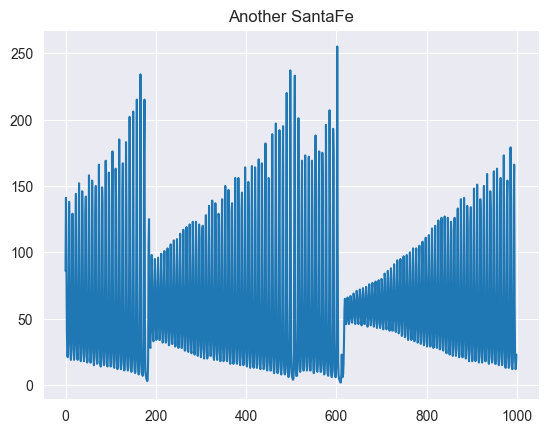

In [11]:
santafe_smol = pd.read_csv("data/santafe.csv")["V1"]

plt.plot(santafe_smol)
plt.title("Another SantaFe")

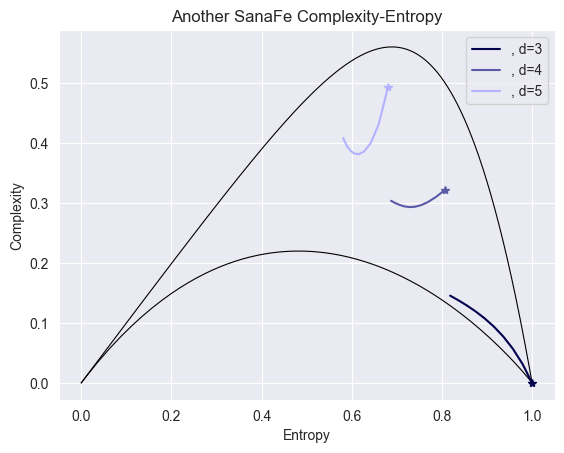

In [12]:
plot_envelope()
plot_complexity_entropy(santafe_smol, title="Another SanaFe Complexity-Entropy")

## FBM

Text(0.5, 1.0, 'Fractional Brownian Motion (fBM)')

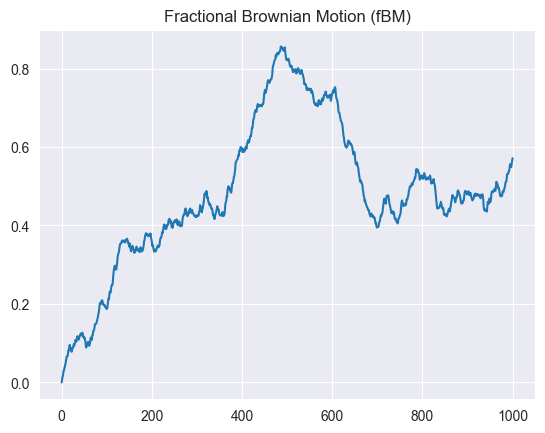

In [13]:
from fbm import FBM


fbm = FBM(n=10**3, hurst=0.75, method='hosking').fbm()
plt.plot(fbm)
plt.title("Fractional Brownian Motion (fBM)")

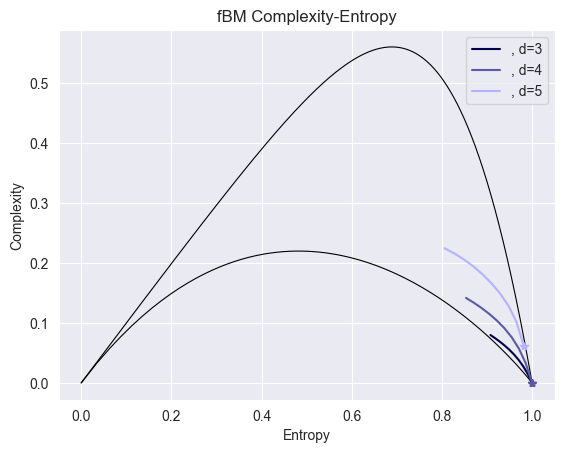

In [14]:
plot_envelope()
plot_complexity_entropy(fbm, title="fBM Complexity-Entropy")

## All in One

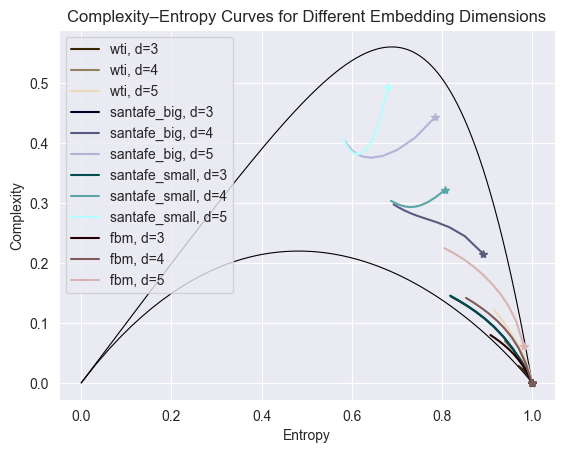

In [15]:
plot_envelope()
plot_complexity_entropy(wti_values, df_name="wti", color="darkgoldenrod")
plot_complexity_entropy(santafe[0], df_name="santafe_big", color="navy")
plot_complexity_entropy(santafe_smol, df_name="santafe_small", color="aqua")
plot_complexity_entropy(fbm, df_name="fbm", color="maroon")


## White noise or smth

Text(0.5, 1.0, 'White Noise')

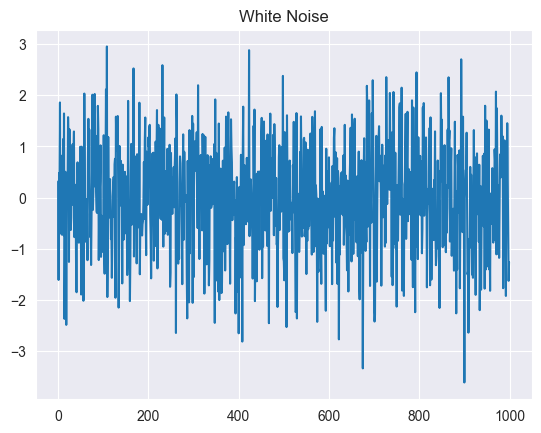

In [16]:
from random import gauss

white_noise = pd.Series([gauss(0.0, 1.0) for _ in range(1000)])
white_noise.plot()
plt.title("White Noise")

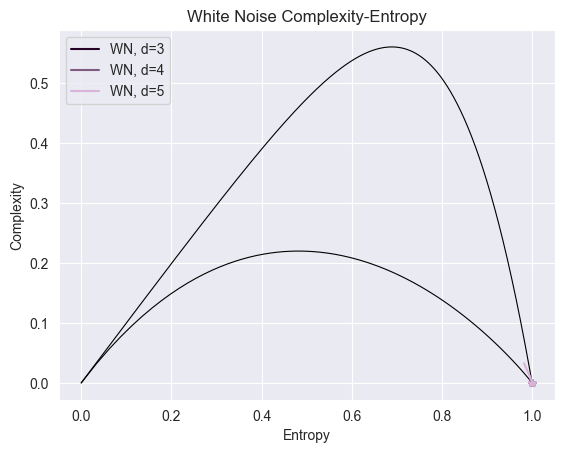

In [17]:
plot_envelope()
plot_complexity_entropy(white_noise, df_name="WN", color="purple", title="White Noise Complexity-Entropy")

## sin(x)

Text(0.5, 1.0, 'Sine')

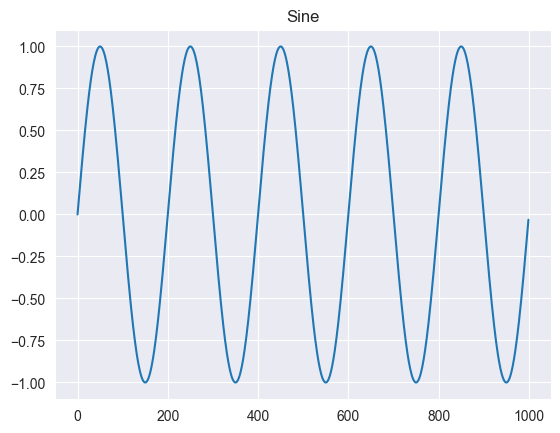

In [18]:
sample_rate = 1000
f = 5
sample_size = 1000

x = np.arange(sample_size)
sine = np.sin(2 * np.pi * f * x / sample_rate)

plt.plot(x, sine)
plt.title("Sine")

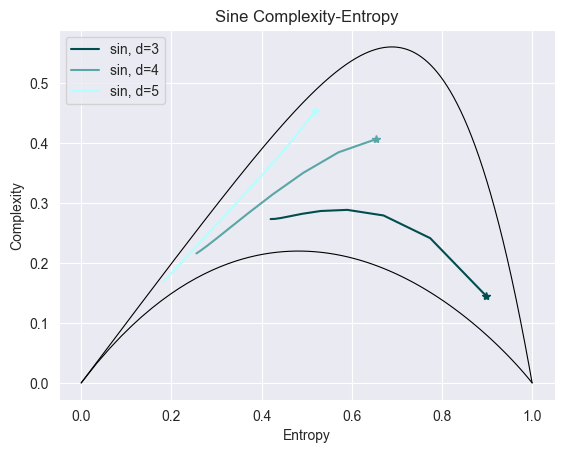

In [19]:
plot_envelope()
plot_complexity_entropy(sine, df_name="sin", color="cyan", title="Sine Complexity-Entropy")

## Constant

Text(0.5, 1.0, 'Constant Value')

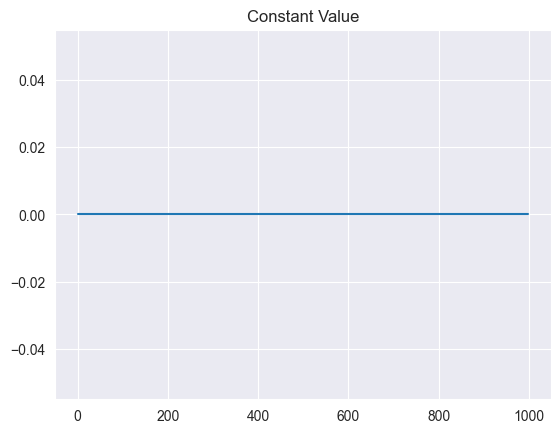

In [20]:
constant = pd.Series([0.0 for _ in range(1000)])
plt.plot(constant)
plt.title("Constant Value")

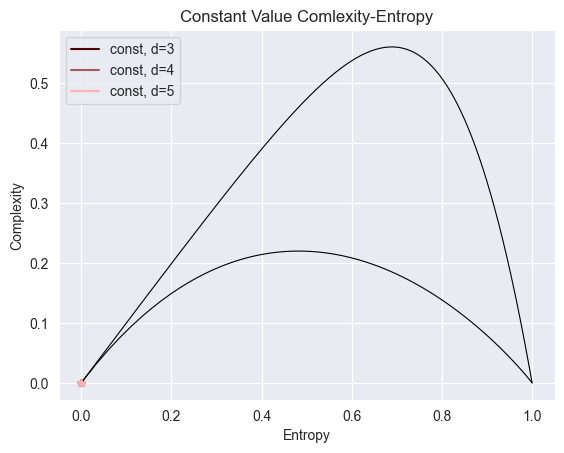

In [21]:
plot_envelope()
plot_complexity_entropy(constant, df_name="const", color="red", title="Constant Value Comlexity-Entropy")

# DBSCAN

    entropy  complexity       class
0  0.995507    0.003902       noise
1  0.995507    0.003902       noise
2  0.995507    0.003902       noise
3  0.812618    0.123806  stochastic
4  0.886271    0.080175  stochastic
Number of rows: 15
Unique cluster labels found: [-1  0  1  2  3]


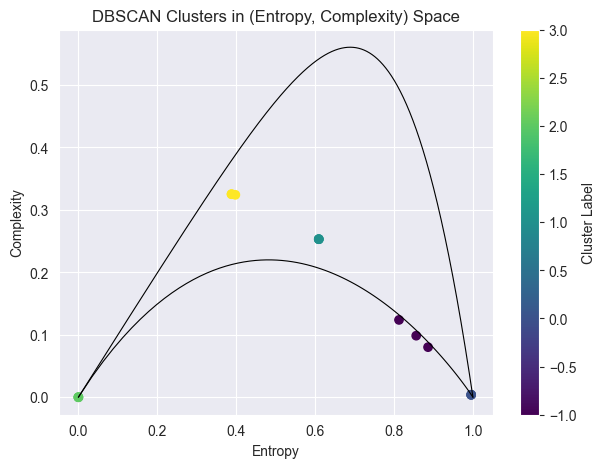

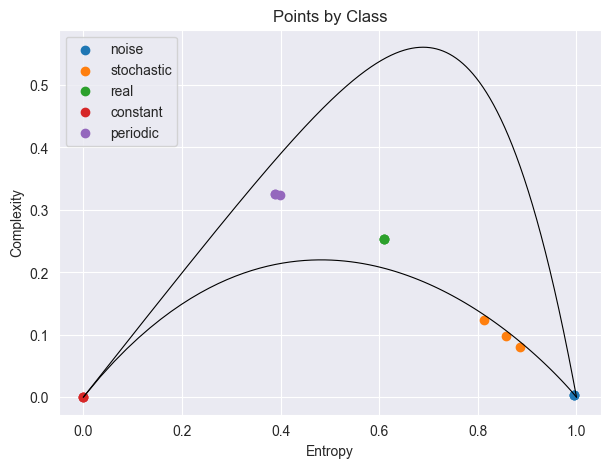

In [22]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from scipy.special import factorial  # if needed in your external functions
import matplotlib.pyplot as plt


def generate_fbm(H, length=2**17):
    """Generate Fractional Brownian Motion using Hosking's method."""
    f = FBM(n=length, hurst=H, method='hosking')
    return f.fbm()

###############################
# Required external functions #
###############################
# Assume these functions are defined somewhere in your code:
# generate_fbm(H, length)
# logistic_map(a, length, transient)
# levy_stable_random(alpha, beta, size)
# uniform_noise(size)
# calc_complexity_entropy(ts, embedding_dim)
# Each function uses an embedding_dim <= 5 internally.

#################################
# 1) Prepare all needed categories
#################################

embedding_dim = 5
assert embedding_dim <= 5, "Embedding dimension must be <= 5."

length = 2**10  # Small sample size

data_records = []

# 1. Random noise
for _ in range(3):
    # ts = uniform_noise(size=length)
    h, c = op.renyi_complexity_entropy(white_noise, embedding_dim)
    data_records.append([h, c, 'noise'])

# 2. Stochastic (Fractional Brownian motion)
for _ in range(3):
    ts = generate_fbm(H=0.5, length=length)
    ent, comp = op.renyi_complexity_entropy(ts, embedding_dim)
    data_records.append([ent, comp, 'stochastic'])

# # Stochastic (Logistic map)
# for _ in range(3):
#     ts = logistic_map(a=4.0, length=length, transient=200)
#     ent, comp = op.renyi_complexity_entropy(ts, embedding_dim)
#     data_records.append([ent, comp, 'stochastic'])

# 3. Real data (placeholder: random walk)
for _ in range(3):
    # real_ts = np.cumsum(np.random.randn(length))
    ent, comp = op.renyi_complexity_entropy(santafe[0], embedding_dim)
    data_records.append([ent, comp, 'real'])

# 4. Constant
for _ in range(3):
    # val = np.random.uniform(-1, 1)
    val = [0 for _ in range(length)]
    ts = np.full(length, val)
    ent, comp = op.renyi_complexity_entropy(ts, embedding_dim)
    data_records.append([ent, comp, 'constant'])

# 5. Periodic (sine wave)
for _ in range(3):
    freq = np.random.randint(1, 10)
    t = np.linspace(0, 1, length)
    wave = np.sin(2 * np.pi * freq * t)
    ent, comp = op.renyi_complexity_entropy(wave, embedding_dim)
    data_records.append([ent, comp, 'periodic'])

# Convert to DataFrame
columns = ['entropy', 'complexity', 'class']
df = pd.DataFrame(data_records, columns=columns)
print(df.head())
print("Number of rows:", len(df))

######################
# 2) Run DBSCAN
######################
X = df[['entropy', 'complexity']].values
dbscan = DBSCAN(eps=0.02, min_samples=2)
labels = dbscan.fit_predict(X)
df['cluster'] = labels

print("Unique cluster labels found:", np.unique(labels))

###############################
# 3) Visualize the results
###############################

# Plot all points colored by DBSCAN cluster labels
plt.figure(figsize=(7, 5))
plt.scatter(df['entropy'], df['complexity'], c=df['cluster'], marker='o', cmap='viridis')
plt.xlabel('Entropy')
plt.ylabel('Complexity')
plt.title('DBSCAN Clusters in (Entropy, Complexity) Space')
plt.colorbar(label='Cluster Label')
plt.grid(True)
plot_envelope()

plt.show()

# Plot points by original class labels
plt.figure(figsize=(7, 5))
for cls in df['class'].unique():
    subset = df[df['class'] == cls]
    plt.scatter(subset['entropy'], subset['complexity'], label=cls)
plt.xlabel('Entropy')
plt.ylabel('Complexity')
plt.legend()
plt.title('Points by Class')
plt.grid(True)
plot_envelope()
plt.show()


# Fix DBSCAN

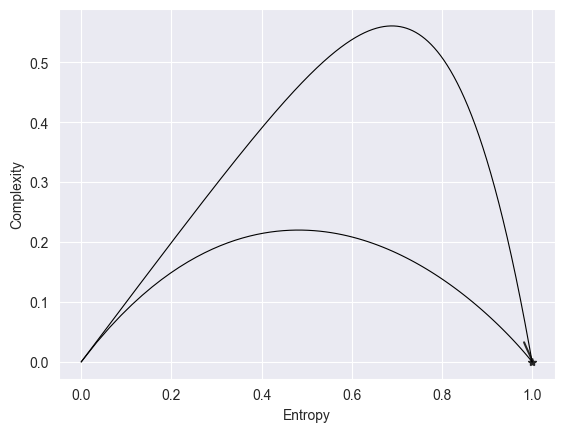

In [23]:
color = "grey"
n=5

dark_color = darken_color(color, 0.7)
light_color = lighten_color(color, 0.7)

# Create a colormap that interpolates between the dark and light variants.
cmap = mcolors.LinearSegmentedColormap.from_list('gradient', [dark_color, light_color])
colors = [cmap(i / (n - 1)) for i in range(n)]

entropies, complexities = zip(*op.renyi_complexity_entropy(
    data=white_noise,
    alpha=np.linspace(0, 1, 10),
    dx=5,
))

plt.plot(
    entropies,
    complexities,
    label="{}, d={}".format("White noise", "5"),
    color=colors[0],
)
plt.plot(entropies[0], complexities[0], "*", color=colors[0])

plot_envelope()

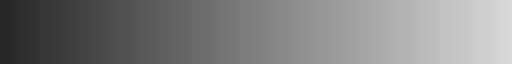

In [24]:
mcolors.LinearSegmentedColormap.from_list('gradient', [dark_color, light_color])

## Just plenty of dx

/Users/hq-mpw74l3xgv/Library/Caches/pypoetry/virtualenvs/bach-thesis-jecnQVtK-py3.11/lib/python3.11/site-packages/ordpy/ordpy.py:1013: RuntimeWarning: invalid value encountered in scalar divide
  s += [(1/(1-alpha_))*np.log(np.sum(probabilities**alpha_))/smax]
/Users/hq-mpw74l3xgv/Library/Caches/pypoetry/virtualenvs/bach-thesis-jecnQVtK-py3.11/lib/python3.11/site-packages/ordpy/ordpy.py:1015: RuntimeWarning: invalid value encountered in scalar divide
  s += [-np.sum(probabilities*np.log(probabilities))/smax]


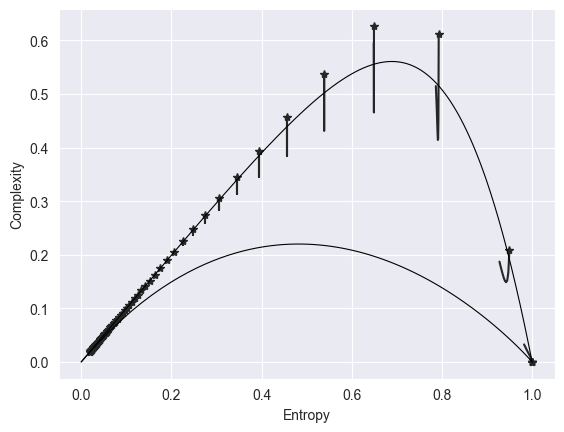

In [25]:
for dx in range(1, 100):
    entropies, complexities = zip(*op.renyi_complexity_entropy(
        data=white_noise,
        alpha=np.linspace(0, 1, 10),
        dx=dx,
    ))

    plt.plot(
        entropies,
        complexities,
        label="{}, d={}".format("White noise", "5"),
        color=colors[0],
    )
    plt.plot(entropies[0], complexities[0], "*", color=colors[0])

plot_envelope()

## Back to Fixing

### Check if Multiple Points Present

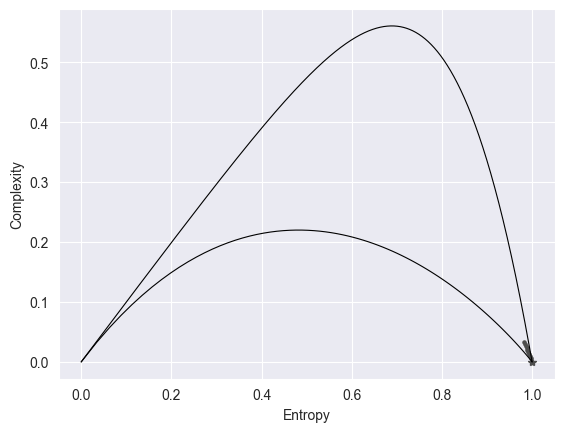

In [26]:
color = "white"
n=5

dark_color = darken_color(color, 0.7)
light_color = lighten_color(color, 0.7)

# Create a colormap that interpolates between the dark and light variants.
cmap = mcolors.LinearSegmentedColormap.from_list('gradient', [dark_color, light_color])
colors = [cmap(i / (n - 1)) for i in range(n)]

entropies, complexities = zip(*op.renyi_complexity_entropy(
    data=white_noise,
    alpha=np.linspace(0, 1, 10),
    dx=5,
))

plt.scatter(
    entropies,
    complexities,
    s=5,
    label="{}, d={}".format("White noise", "5"),
    color=colors[0],
)
plt.plot(entropies[0], complexities[0], "*", color=colors[0])

plot_envelope()

## New Train

In [27]:
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from scipy.special import factorial  # if needed in your external functions
import matplotlib.pyplot as plt


## WTI

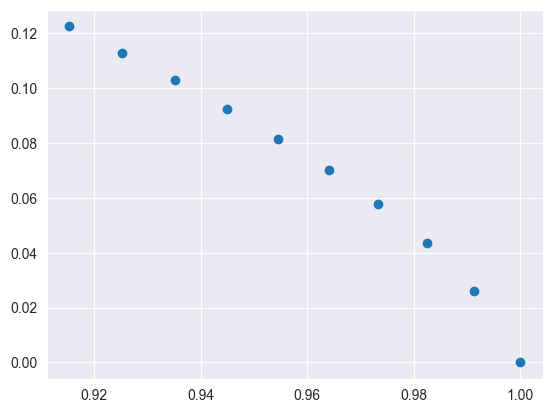

In [28]:
data_records = []

def get_complexity_entropy(data: list[float], d=5) -> dict[str, list[float]]:
    entropies, complexities = zip(*op.renyi_complexity_entropy(
        data=data,
        alpha=np.linspace(0, 1, 10),
        dx=d,
    ))

    return {"entropy": entropies, "complexity": complexities}

ce_example = get_complexity_entropy(wti_values)
plt.scatter(ce_example["entropy"], ce_example["complexity"])

In [29]:
len(get_complexity_entropy(wti_values))

2

In [30]:
complexity_entropy = get_complexity_entropy(wti_values)
complexity_entropy["class"] = ["real" for _ in range(len(complexity_entropy["entropy"]))]
print(complexity_entropy)

{'entropy': (np.float64(1.0), np.float64(0.9913519415534735), np.float64(0.9824635356696431), np.float64(0.9733490703845433), np.float64(0.9640278531024637), np.float64(0.9545244235751124), np.float64(0.9448685238999419), np.float64(0.9350947795710322), np.float64(0.9252420690615327), np.float64(0.9153525914217395)), 'complexity': (np.float64(-0.0), np.float64(0.02609423365839487), np.float64(0.043704024245277084), np.float64(0.0577215890620908), np.float64(0.0700790988650005), np.float64(0.0815648809437544), np.float64(0.09248437430869583), np.float64(0.10293816374626638), np.float64(0.11294547014321393), np.float64(0.12249901241985646)), 'class': ['real', 'real', 'real', 'real', 'real', 'real', 'real', 'real', 'real', 'real']}


In [31]:

# df = pd.DataFrame(complexity_entropy)
# df

## SantaFe

In [32]:
ce = get_complexity_entropy(santafe[0])
ce["class"] = ["real" for _ in range(len(complexity_entropy["entropy"]))]
# df = pd.concat([df, pd.DataFrame(ce)])
df = pd.DataFrame.from_dict(ce)
df

,entropy,complexity,class
0,0.785631,0.443823,real
1,0.740242,0.408975,real
2,0.700973,0.388708,real
3,0.668800,0.378618,real
4,0.643556,0.375671,real
5,0.624305,0.377537,real
6,0.609834,0.382436,real
7,0.598985,0.389059,real
8,0.590803,0.396490,real
9,0.584561,0.404117,real


## FBM

In [33]:
ce = get_complexity_entropy(fbm)
ce["class"] = ["stochastic" for _ in range(len(ce["entropy"]))]
ce

{'entropy': (np.float64(0.9818252684987262),
  np.float64(0.9650386887473186),
  np.float64(0.9475104802768045),
  np.float64(0.9292244335719204),
  np.float64(0.9101810415669013),
  np.float64(0.8904054379629537),
  np.float64(0.8699555784946142),
  np.float64(0.8489291219461617),
  np.float64(0.8274670284773278),
  np.float64(0.805751933923507)),
 'complexity': (np.float64(0.061015118399653054),
  np.float64(0.10211876135977278),
  np.float64(0.12864398806708133),
  np.float64(0.14889459305370373),
  np.float64(0.16593997039971922),
  np.float64(0.180909405604705),
  np.float64(0.194182320347725),
  np.float64(0.20587099224150254),
  np.float64(0.2160198221914573),
  np.float64(0.22468292369714532)),
 'class': ['stochastic',
  'stochastic',
  'stochastic',
  'stochastic',
  'stochastic',
  'stochastic',
  'stochastic',
  'stochastic',
  'stochastic',
  'stochastic']}

In [34]:
df = pd.concat([df, pd.DataFrame(ce)])
df

,entropy,complexity,class
0,0.785631,0.443823,real
1,0.740242,0.408975,real
2,0.700973,0.388708,real
3,0.668800,0.378618,real
4,0.643556,0.375671,real
5,0.624305,0.377537,real
6,0.609834,0.382436,real
7,0.598985,0.389059,real
8,0.590803,0.396490,real
9,0.584561,0.404117,real


## White Noise

In [35]:
ce = get_complexity_entropy(white_noise)
ce["class"] = ["noise" for _ in range(len(ce["entropy"]))]
ce

{'entropy': (np.float64(1.0),
  np.float64(0.997764650442261),
  np.float64(0.9955969089570185),
  np.float64(0.9934953448900172),
  np.float64(0.9914583958285318),
  np.float64(0.9894843954051912),
  np.float64(0.987571598282117),
  np.float64(0.9857182023368763),
  np.float64(0.9839223681445816),
  np.float64(0.9821822359025432)),
 'complexity': (np.float64(3.242244738259823e-16),
  np.float64(0.006014015525618499),
  np.float64(0.010240511070100915),
  np.float64(0.013759141431754924),
  np.float64(0.017003772630851573),
  np.float64(0.02015539707643839),
  np.float64(0.023285777931276595),
  np.float64(0.02641858493600199),
  np.float64(0.02955707046783222),
  np.float64(0.0326967240517547)),
 'class': ['noise',
  'noise',
  'noise',
  'noise',
  'noise',
  'noise',
  'noise',
  'noise',
  'noise',
  'noise']}

In [36]:
df = pd.concat([df, pd.DataFrame(ce)])
df

,entropy,complexity,class
0,0.785631,4.438232e-01,real
1,0.740242,4.089752e-01,real
2,0.700973,3.887084e-01,real
3,0.668800,3.786184e-01,real
4,0.643556,3.756710e-01,real
5,0.624305,3.775373e-01,real
6,0.609834,3.824364e-01,real
7,0.598985,3.890594e-01,real
8,0.590803,3.964895e-01,real
9,0.584561,4.041167e-01,real


## Constant

In [37]:
ce = get_complexity_entropy(constant)
ce["class"] = ["constant" for _ in range(len(ce["entropy"]))]
ce

{'entropy': (np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(-0.0)),
 'complexity': (np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(0.0),
  np.float64(-0.0)),
 'class': ['constant',
  'constant',
  'constant',
  'constant',
  'constant',
  'constant',
  'constant',
  'constant',
  'constant',
  'constant']}

In [38]:
df = pd.concat([df, pd.DataFrame(ce)])
df

,entropy,complexity,class
0,0.785631,4.438232e-01,real
1,0.740242,4.089752e-01,real
2,0.700973,3.887084e-01,real
3,0.668800,3.786184e-01,real
4,0.643556,3.756710e-01,real
5,0.624305,3.775373e-01,real
6,0.609834,3.824364e-01,real
7,0.598985,3.890594e-01,real
8,0.590803,3.964895e-01,real
9,0.584561,4.041167e-01,real


## Periodic

In [39]:
ce = get_complexity_entropy(sine)
ce["class"] = ["periodic" for _ in range(len(ce["entropy"]))]
ce

{'entropy': (np.float64(0.5190414486948031),
  np.float64(0.4583091524859623),
  np.float64(0.39791166975196485),
  np.float64(0.3419690121220545),
  np.float64(0.29409004240588044),
  np.float64(0.2560504275516216),
  np.float64(0.22756163232121343),
  np.float64(0.20704751421349785),
  np.float64(0.19258021057881725),
  np.float64(0.18244276953443916)),
 'complexity': (np.float64(0.45309617871501984),
  np.float64(0.39584269357685176),
  np.float64(0.3441744335180246),
  np.float64(0.2981760708633879),
  np.float64(0.259272559874212),
  np.float64(0.2283960401318401),
  np.float64(0.20525367911993067),
  np.float64(0.18861803061071397),
  np.float64(0.1769577063995535),
  np.float64(0.16887911351646195)),
 'class': ['periodic',
  'periodic',
  'periodic',
  'periodic',
  'periodic',
  'periodic',
  'periodic',
  'periodic',
  'periodic',
  'periodic']}

In [40]:
df = pd.concat([df, pd.DataFrame(ce)])
df

,entropy,complexity,class
0,0.785631,4.438232e-01,real
1,0.740242,4.089752e-01,real
2,0.700973,3.887084e-01,real
3,0.668800,3.786184e-01,real
4,0.643556,3.756710e-01,real
5,0.624305,3.775373e-01,real
6,0.609834,3.824364e-01,real
7,0.598985,3.890594e-01,real
8,0.590803,3.964895e-01,real
9,0.584561,4.041167e-01,real


Number of rows: 50
Unique cluster labels found: [-1  0  1  2  3]


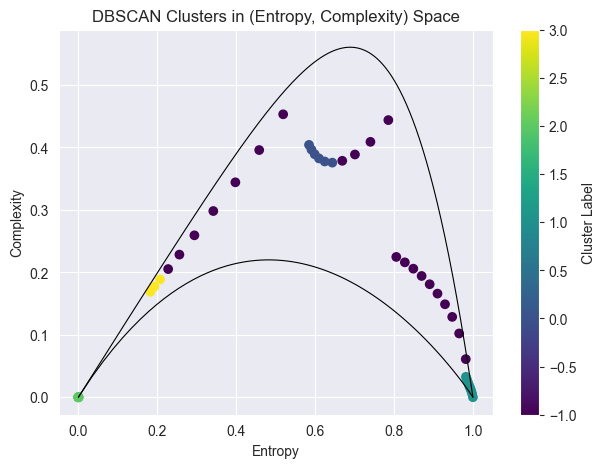

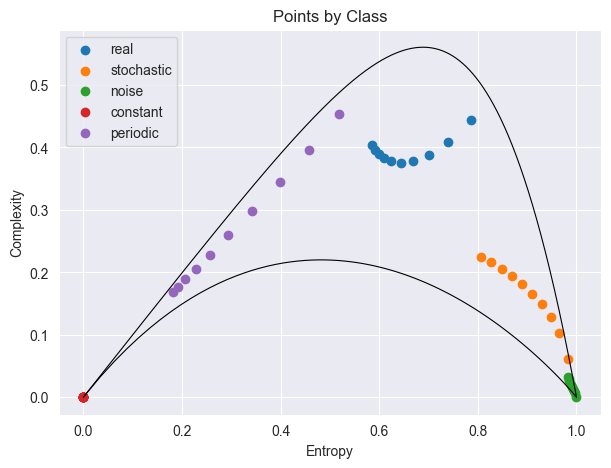

In [41]:

print("Number of rows:", len(df))

X = df[['entropy', 'complexity']].values
dbscan = DBSCAN(eps=0.02, min_samples=2)
labels = dbscan.fit_predict(X)
df['cluster'] = labels

print("Unique cluster labels found:", np.unique(labels))

plt.figure(figsize=(7, 5))
plt.scatter(df['entropy'], df['complexity'], c=df['cluster'], marker='o', cmap='viridis')
plt.xlabel('Entropy')
plt.ylabel('Complexity')
plt.title('DBSCAN Clusters in (Entropy, Complexity) Space')
plt.colorbar(label='Cluster Label')
plt.grid(True)
plot_envelope()

plt.show()

plt.figure(figsize=(7, 5))
for cls in df['class'].unique():
    subset = df[df['class'] == cls]
    plt.scatter(subset['entropy'], subset['complexity'], label=cls)
plt.xlabel('Entropy')
plt.ylabel('Complexity')
plt.legend()
plt.title('Points by Class')
plt.grid(True)
plot_envelope()
plt.show()


In [42]:
df.drop(["cluster"], axis=1).reset_index(drop=True)

,entropy,complexity,class
0,0.785631,4.438232e-01,real
1,0.740242,4.089752e-01,real
2,0.700973,3.887084e-01,real
3,0.668800,3.786184e-01,real
4,0.643556,3.756710e-01,real
5,0.624305,3.775373e-01,real
6,0.609834,3.824364e-01,real
7,0.598985,3.890594e-01,real
8,0.590803,3.964895e-01,real
9,0.584561,4.041167e-01,real


# New Clustering

KMeans Silhouette Score: 0.731


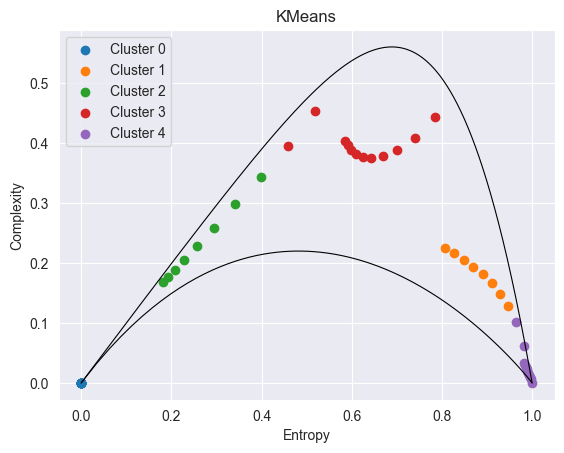

DBSCAN Silhouette Score: 0.334


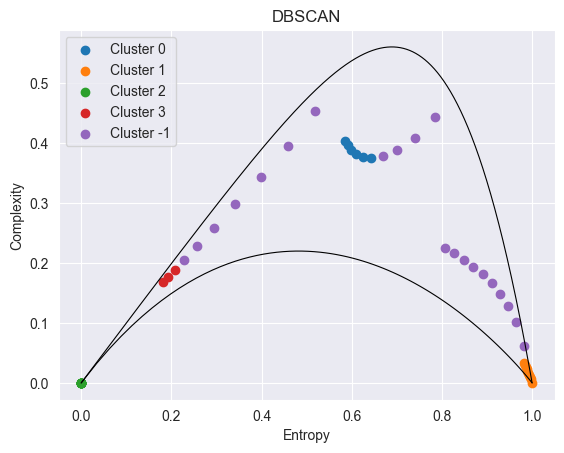

Agglomerative (Ward) Silhouette Score: 0.726


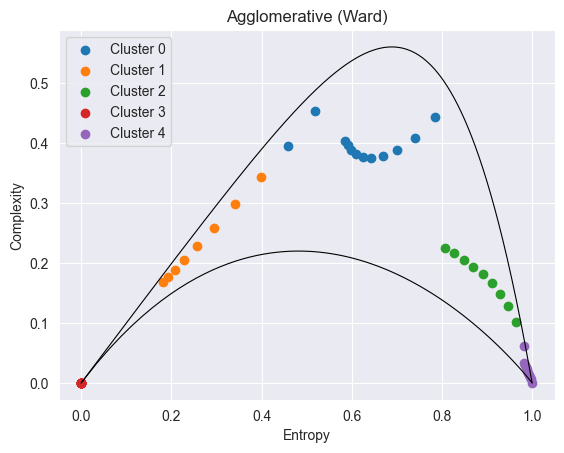

In [43]:
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

X = df[['entropy','complexity']].values

methods = [
    ('KMeans', KMeans(n_clusters=5, n_init=10, random_state=0)),
    ('DBSCAN', DBSCAN(eps=0.02, min_samples=2)),
    ('Agglomerative (Ward)', AgglomerativeClustering(n_clusters=5, linkage='ward'))
]

for name, model in methods:
    labels = model.fit_predict(X)
    if name == "KMeans":
        kmeans_model = model

    score = silhouette_score(X, labels)
    print(f"{name} Silhouette Score: {score:.3f}")

    plt.figure()
    for lbl in set(labels):
        mask = labels == lbl
        plt.scatter(X[mask, 0], X[mask, 1], label=f'Cluster {lbl}')
    plt.title(name)
    plt.xlabel('Complexity')
    plt.ylabel('Entropy')
    plt.legend()
    plot_envelope()
    plt.show()

In [46]:
import joblib   # install with: pip install joblib

# … your loop from earlier, which leaves kmeans_model fitted …

# --- EXPORT -------------------------------------------------
out_path = "models/kmeans_entropy_complexity.pkl"
joblib.dump(kmeans_model, out_path)       # → writes file next to your script
print(f"K-means model saved to: {out_path}")


K-means model saved to: models/kmeans_entropy_complexity.pkl


In [44]:
# from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
# import pandas as pd
# import numpy as np
# from shapely.geometry import MultiPoint, Point
# import matplotlib.pyplot as plt
#
# # — assume df is already loaded and has columns ['complexity','entropy','class'] —
#
# # 1) Build true‑class hulls
# hulls = {}
# for cls, grp in df.groupby('class'):
#     pts = [tuple(x) for x in grp[['complexity','entropy']].values]
#     hulls[cls] = MultiPoint(pts).convex_hull    # always a valid geometry
#
# # 2) Define your three clustering models
# methods = [
#     ('KMeans',            KMeans(n_clusters=5, n_init=10, random_state=0)),
#     ('DBSCAN',            DBSCAN(eps=0.02, min_samples=2)),
#     ('Agglomerative (W)', AgglomerativeClustering(n_clusters=5, linkage='ward')),
# ]
#
# X = df[['complexity','entropy']].values
#
# for name, model in methods:
#     pred = model.fit_predict(X)
#
#     # 3) Map each predicted cluster → the majority true class in that cluster
#     cluster_to_true = {}
#     for cluster_label in np.unique(pred):
#         members = df.loc[pred == cluster_label, 'class']
#         # pandas.mode() gives the most frequent class
#         cluster_to_true[cluster_label] = members.mode()[0]
#
#     # 4) Collect distances for points whose assigned class ≠ their true class
#     dists = []
#     for i, (c, e) in enumerate(X):
#         true_cls = df.loc[i, 'class']
#         assigned_cls = cluster_to_true[pred[i]]
#         if assigned_cls != true_cls:
#             dists.append(hulls[true_cls].distance(Point(c, e)))
#
#     severity = float(np.mean(dists)) if dists else 0.0
#     print(f"{name} Hallucination Severity: {severity:.3f}")
#
#     # 5) Plot the histogram of those hallucination distances
#     plt.figure()
#     plt.hist(dists, bins=15)
#     plt.title(f"{name} hallucination‑distance distribution")
#     plt.xlabel("Distance to true hull")
#     plt.ylabel("Count")
#     plt.show()


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

# MIACR

In [50]:
import pandas as pd

miacr = pd.read_excel('data/miacr.xlsx', nrows=6000)
miacr.head()

,Дата,1 день,от 2 до 7 дн.,от 8 до 30 дн.,от 31 до 90 дн.,от 91 до 180 дн.,от 181 дн. до 1 года
0,2025-04-23,20.67,—,—,—,—,—
1,2025-04-22,20.65,—,—,—,—,—
2,2025-04-21,20.65,21.95,—,—,—,—
3,2025-04-18,20.64,—,—,—,—,—
4,2025-04-17,20.62,—,—,—,—,—


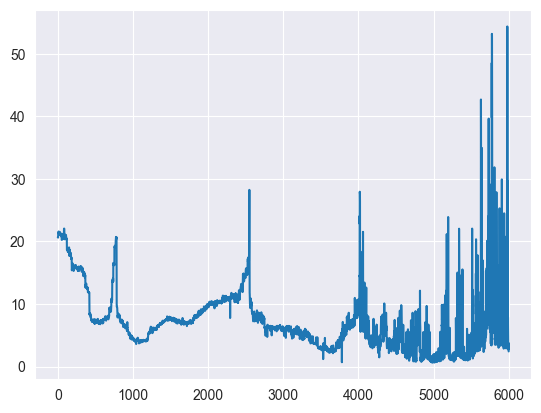

In [52]:
plt.plot(miacr["1 день"])

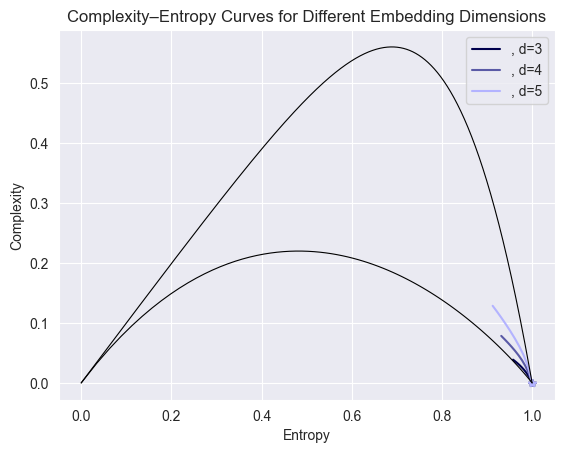

In [56]:
plot_complexity_entropy(miacr["1 день"])
plot_envelope()

[1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,
 2,
 3,
 1,


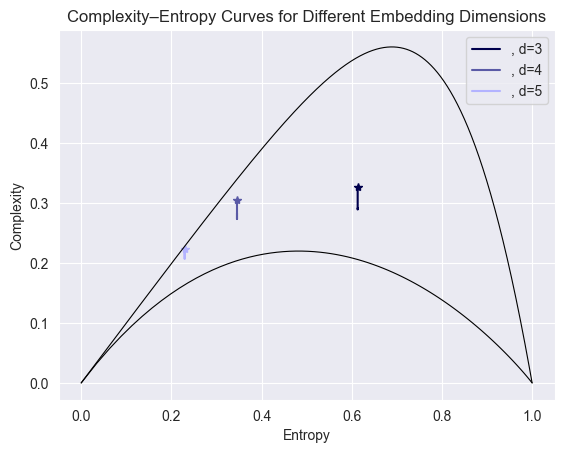

In [62]:
plot_complexity_entropy(np.randn(100))
plot_envelope()

# Adding Image